# Siklus Kerentanan Sosial: Analisis Kausalitas Multivariat Antara Kemiskinan, Disintegrasi Keluarga, dan Kekerasan Terhadap Anak (2024)
------


Vibe Coders:
- Marchell Adi Pratama (672023081)
- Fauzhan Ariel Gibran S (672023214)

------



DATASET:
- Jumlah Penduduk Miskin (Ribu Jiwa) Menurut Provinsi dan Daerah: https://www.bps.go.id/id/statistics-table/2/MTg1IzI=/jumlah-penduduk-miskin--ribu-jiwa--menurut-provinsi-dan-daerah.html
- Jumlah Perceraian Menurut Provinsi dan Faktor Penyebab
Perceraian: https://www.bps.go.id/id/statistics-table/3/YVdoU1IwVmlTM2h4YzFoV1psWkViRXhqTlZwRFVUMDkjMyMwMDAw/jumlah-perceraian-menurut-provinsi-dan-faktor-penyebab-perceraian--perkara-.html?year=2024
- Jumlah Kasus dan Korban Kekerasan terhadap Anak (Simfoni PPA): https://siga.kemenpppa.go.id/dataset?ids=MTIyMg==&entity=cHJvdmluY2U=

# Setup

Import Library

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. LOAD & CLEAN DATA

1.1 Poverty Data

In [ ]:
file_pov = "Jumlah Penduduk Miskin (Ribu Jiwa) Menurut Provinsi dan Daerah, 2024.csv"
df_pov = pd.read_csv(file_pov, header=None)
df_pov_clean = df_pov.iloc[5:, [0, 7]].copy()
df_pov_clean.columns = ['Provinsi', 'Jml_Miskin_Ribu']
df_pov_clean.replace('-', np.nan, inplace=True)
df_pov_clean['Jml_Miskin_Ribu'] = pd.to_numeric(df_pov_clean['Jml_Miskin_Ribu'])
df_pov_clean['Provinsi'] = df_pov_clean['Provinsi'].str.strip().str.upper()
df_pov_clean['Provinsi'] = df_pov_clean['Provinsi'].replace({'KEP. BANGKA BELITUNG': 'KEPULAUAN BANGKA BELITUNG'})

1.2 Divorce Data

In [ ]:
file_div = "Jumlah Perceraian Menurut Provinsi dan Faktor Penyebab Perceraian (perkara), 2024.csv"
df_div = pd.read_csv(file_div)
def clean_currency(x):
    if isinstance(x, str):
        return pd.to_numeric(x.replace('.', '').replace(',', ''), errors='coerce')
    return x
df_div['Jml_Cerai_Total'] = df_div['Fakor Perceraian - Jumlah'].apply(clean_currency)
df_div['Jml_Cerai_Ekonomi'] = df_div['Fakor Perceraian - Ekonomi'].apply(clean_currency)
df_div['Jml_Cerai_KDRT'] = df_div['Fakor Perceraian - Kekerasan Dalam Rumah Tangga'].apply(clean_currency)
df_div_clean = df_div[['Provinsi', 'Jml_Cerai_Total', 'Jml_Cerai_Ekonomi', 'Jml_Cerai_KDRT']].copy()
df_div_clean.fillna(0, inplace=True)
df_div_clean['Provinsi'] = df_div_clean['Provinsi'].str.strip().str.upper()
df_div_clean['Provinsi'] = df_div_clean['Provinsi'].replace({
    'DI YOGYAKARTA': 'DI YOGYAKARTA',
    'DKI JAKARTA': 'DKI JAKARTA',
    'KEP. BANGKA BELITUNG': 'KEPULAUAN BANGKA BELITUNG'
})

1.3 Violence Data

In [ ]:
file_viol = "Jumlah Kasus dan Korban Kekerasan terhadap Anak menurut Tahun Penginputan-2024-Nasional.xlsx"
df_viol = pd.read_excel(file_viol)
df_viol_clean = df_viol[['Cakupan', 'Jumlah Kasus']].copy()
df_viol_clean.columns = ['Provinsi', 'Jml_Kekerasan_Anak']
df_viol_clean['Provinsi'] = df_viol_clean['Provinsi'].str.strip().str.upper()
df_viol_clean = df_viol_clean[~df_viol_clean['Provinsi'].isin(['INDONESIA', 'NASIONAL', 'JUMLAH'])]

# 2. Integration

In [ ]:
df_merge1 = pd.merge(df_pov_clean, df_div_clean, on='Provinsi', how='inner')
df_final = pd.merge(df_merge1, df_viol_clean, on='Provinsi', how='inner')
df_final = df_final[df_final['Provinsi'] != 'INDONESIA']

# 3. ANALYSIS

In [ ]:
# Correlation
corr_matrix = df_final[['Jml_Miskin_Ribu', 'Jml_Cerai_Total', 'Jml_Cerai_Ekonomi', 'Jml_Kekerasan_Anak']].corr()

# Clustering
features = ['Jml_Miskin_Ribu', 'Jml_Cerai_Total', 'Jml_Kekerasan_Anak']
X = df_final[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_final['Cluster'] = kmeans.fit_predict(X_scaled)

print("Correlation Matrix:")
print(corr_matrix)
print("\nCluster Centers (Scaled):")
print(kmeans.cluster_centers_)
print("\nFirst 5 rows with Cluster:")
print(df_final[['Provinsi', 'Cluster', 'Jml_Miskin_Ribu', 'Jml_Cerai_Total', 'Jml_Kekerasan_Anak']].head())

Correlation Matrix:
                    Jml_Miskin_Ribu  Jml_Cerai_Total  Jml_Cerai_Ekonomi  \
Jml_Miskin_Ribu            1.000000         0.968057           0.946363   
Jml_Cerai_Total            0.968057         1.000000           0.982727   
Jml_Cerai_Ekonomi          0.946363         0.982727           1.000000   
Jml_Kekerasan_Anak         0.813920         0.834265           0.753481   

                    Jml_Kekerasan_Anak  
Jml_Miskin_Ribu               0.813920  
Jml_Cerai_Total               0.834265  
Jml_Cerai_Ekonomi             0.753481  
Jml_Kekerasan_Anak            1.000000  

Cluster Centers (Scaled):
[[-0.47839025 -0.43165677 -0.73030251]
 [ 3.1999694   3.2565157   2.4235231 ]
 [-0.03403289 -0.1045379   0.44034523]]

First 5 rows with Cluster:
         Provinsi  Cluster  Jml_Miskin_Ribu  Jml_Cerai_Total  \
0            ACEH        2           804.53           6103.0   
1  SUMATERA UTARA        2          1228.01          15955.0   
2  SUMATERA BARAT        2        

# 4. PLOTTING (Reproduce checks)

4.1 Heatmap

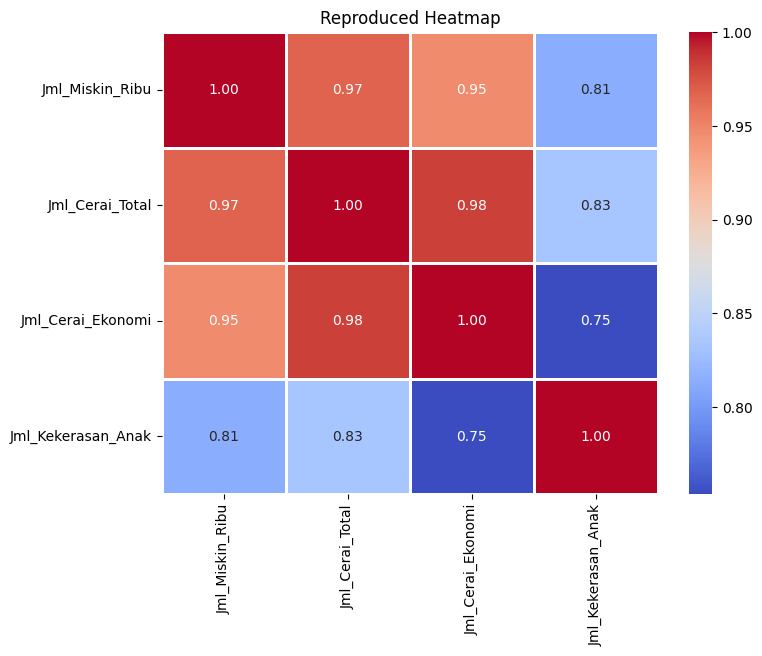

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=1, fmt=".2f")
plt.title('Reproduced Heatmap')
plt.savefig('Reproduced_Heatmap.png')

4.2 Bubble Plot

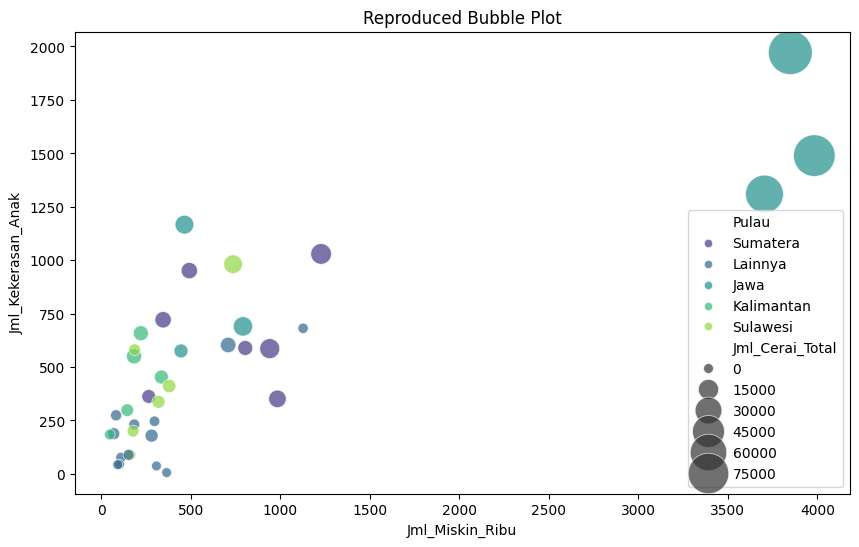

In [ ]:
plt.figure(figsize=(10, 6))
def get_pulau(prov):
    if any(x in prov for x in ['SUMATERA', 'ACEH', 'RIAU', 'JAMBI', 'LAMPUNG']): return 'Sumatera'
    if any(x in prov for x in ['JAWA', 'DKI', 'BANTEN', 'YOGYAKARTA']): return 'Jawa'
    if any(x in prov for x in ['KALIMANTAN']): return 'Kalimantan'
    if any(x in prov for x in ['SULAWESI', 'GORONTALO']): return 'Sulawesi'
    return 'Lainnya'
df_final['Pulau'] = df_final['Provinsi'].apply(get_pulau)
sns.scatterplot(data=df_final, x='Jml_Miskin_Ribu', y='Jml_Kekerasan_Anak', size='Jml_Cerai_Total', hue='Pulau', sizes=(50, 1000), alpha=0.7, palette='viridis')
plt.title('Reproduced Bubble Plot')
plt.savefig('Reproduced_BubblePlot.png')